In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df= pd.read_csv("loan_approval_data.csv")

In [3]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

Applicant_ID          50
Applicant_Income      50
Coapplicant_Income    50
Employment_Status     50
Age                   50
Marital_Status        50
Dependents            50
Credit_Score          50
Existing_Loans        50
DTI_Ratio             50
Savings               50
Collateral_Value      50
Loan_Amount           50
Loan_Term             50
Loan_Purpose          50
Property_Area         50
Education_Level       50
Gender                50
Employer_Category     50
Loan_Approved         50
dtype: int64

In [4]:
cat_coul= df.select_dtypes(include=["str"]).columns
num_coul= df.select_dtypes(include=["float64"]).columns
print(f"catagorical colomns={cat_coul} \n number coloums={num_coul}")

catagorical colomns=Index(['Employment_Status', 'Marital_Status', 'Loan_Purpose', 'Property_Area',
       'Education_Level', 'Gender', 'Employer_Category', 'Loan_Approved'],
      dtype='str') 
 number coloums=Index(['Applicant_ID', 'Applicant_Income', 'Coapplicant_Income', 'Age',
       'Dependents', 'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='str')


In [5]:
from sklearn.impute import SimpleImputer
num_imp= SimpleImputer(strategy='mean')
cat_imp=SimpleImputer(strategy='most_frequent')
df[cat_coul]=cat_imp.fit_transform(df[cat_coul])
df[num_coul]=num_imp.fit_transform(df[num_coul])

In [6]:
df.info()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        1000 non-null   float64
 1   Applicant_Income    1000 non-null   float64
 2   Coapplicant_Income  1000 non-null   float64
 3   Employment_Status   1000 non-null   str    
 4   Age                 1000 non-null   float64
 5   Marital_Status      1000 non-null   str    
 6   Dependents          1000 non-null   float64
 7   Credit_Score        1000 non-null   float64
 8   Existing_Loans      1000 non-null   float64
 9   DTI_Ratio           1000 non-null   float64
 10  Savings             1000 non-null   float64
 11  Collateral_Value    1000 non-null   float64
 12  Loan_Amount         1000 non-null   float64
 13  Loan_Term           1000 non-null   float64
 14  Loan_Purpose        1000 non-null   str    
 15  Property_Area       1000 non-null   str    
 16  Education_Level   

Applicant_ID          0
Applicant_Income      0
Coapplicant_Income    0
Employment_Status     0
Age                   0
Marital_Status        0
Dependents            0
Credit_Score          0
Existing_Loans        0
DTI_Ratio             0
Savings               0
Collateral_Value      0
Loan_Amount           0
Loan_Term             0
Loan_Purpose          0
Property_Area         0
Education_Level       0
Gender                0
Employer_Category     0
Loan_Approved         0
dtype: int64

# EDA

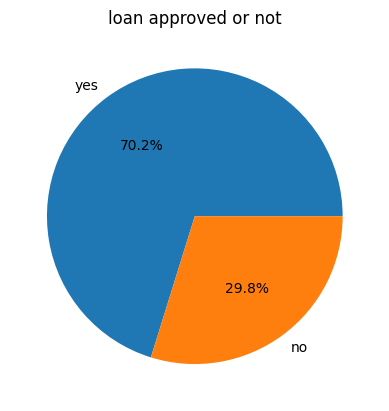

In [7]:
class_count= df["Loan_Approved"].value_counts()
plt.pie(class_count,labels=["yes","no"],autopct="%1.1f%%")
plt.title("loan approved or not")
plt.show()

[Text(0, 0, '621'), Text(0, 0, '379')]

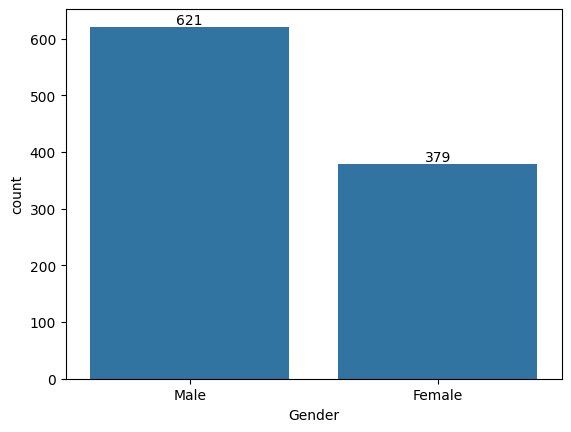

In [8]:
gender_count= df["Gender"].value_counts()
ax=sns.barplot(gender_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '722'), Text(0, 0, '278')]

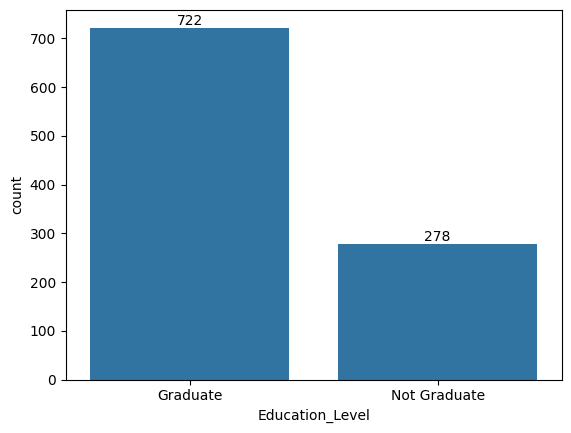

In [9]:
edu_count= df["Education_Level"].value_counts()
cl=sns.barplot(edu_count)
cl.bar_label(cl.containers[0])

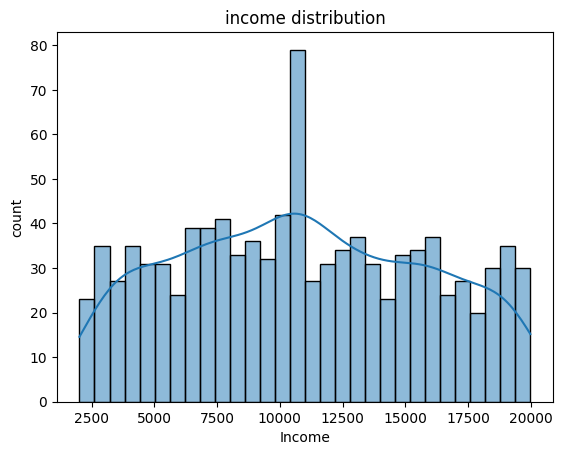

In [10]:
sns.histplot(df['Applicant_Income'],bins=30,kde=True)
plt.xlabel("Income")
plt.ylabel("count")
plt.title("income distribution")
plt.show()

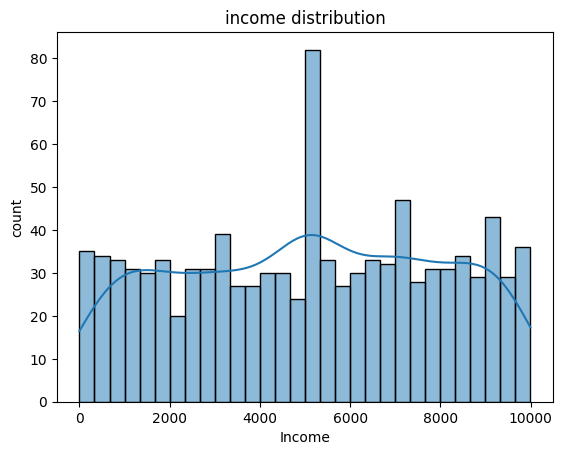

In [11]:
sns.histplot(df['Coapplicant_Income'],bins=30,kde=True)
plt.xlabel("Income")
plt.ylabel("count")
plt.title("income distribution")
plt.show()

In [12]:
df

,Applicant_ID,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,1.0,17795.000000,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.000000,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2.0,2860.000000,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.000000,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,3.0,7390.000000,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.000000,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,4.0,13964.000000,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.000000,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,5.0,13284.000000,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.000000,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,996.0,10852.571579,9092.0,Salaried,58.0,Married,0.0,557.0,0.0,0.59,5370.000000,43563.0,8311.0,72.0,Personal,Urban,Not Graduate,Male,Unemployed,No
996,997.0,3279.000000,6356.0,Self-employed,58.0,Married,1.0,646.0,3.0,0.19,9940.452632,18361.0,22563.0,12.0,Business,Urban,Graduate,Female,Government,No
997,998.0,15192.000000,8433.0,Contract,48.0,Single,1.0,666.0,1.0,0.40,8581.000000,41335.0,16203.0,24.0,Home,Rural,Graduate,Male,MNC,No
998,999.0,9083.000000,7380.0,Unemployed,50.0,Single,1.0,748.0,3.0,0.31,13491.000000,8933.0,10290.0,36.0,Personal,Urban,Graduate,Male,Private,Yes


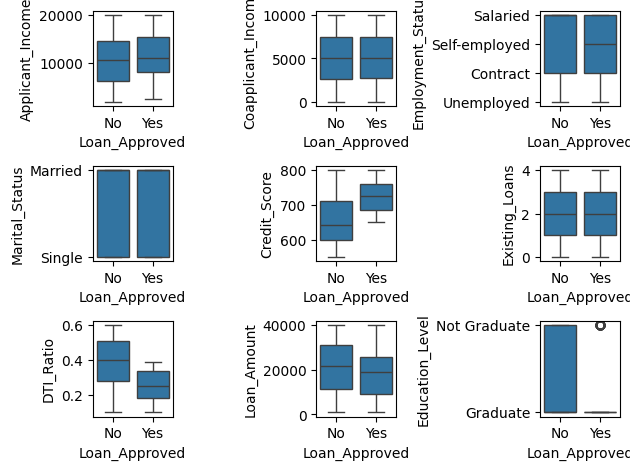

In [13]:
fig,axes=plt.subplots(3,3)
sns.boxplot(ax=axes[0,0],data=df,x="Loan_Approved",y="Applicant_Income")
sns.boxplot(ax=axes[0,1],data=df,x="Loan_Approved",y="Coapplicant_Income")
sns.boxplot(ax=axes[0,2],data=df,x="Loan_Approved",y="Employment_Status")
sns.boxplot(ax=axes[1,0],data=df,x="Loan_Approved",y="Marital_Status")
sns.boxplot(ax=axes[1,1],data=df,x="Loan_Approved",y="Credit_Score")
sns.boxplot(ax=axes[1,2],data=df,x="Loan_Approved",y="Existing_Loans")
sns.boxplot(ax=axes[2,0],data=df,x="Loan_Approved",y="DTI_Ratio")
sns.boxplot(ax=axes[2,1],data=df,x="Loan_Approved",y="Loan_Amount")
sns.boxplot(ax=axes[2,2],data=df,x="Loan_Approved",y="Education_Level")
plt.tight_layout()
plt.show()

In [14]:
df=df.drop("Applicant_ID",axis=1)

In [15]:
df.head()

,Applicant_Income,Coapplicant_Income,Employment_Status,Age,Marital_Status,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,Loan_Term,Loan_Purpose,Property_Area,Education_Level,Gender,Employer_Category,Loan_Approved
0,17795.0,1387.0,Salaried,51.0,Married,0.0,637.0,4.0,0.53,19403.0,45638.0,16619.0,84.0,Personal,Urban,Not Graduate,Female,Private,No
1,2860.0,2679.0,Salaried,46.0,Married,3.0,621.0,2.0,0.30,2580.0,49272.0,38687.0,48.0,Car,Semiurban,Graduate,Male,Private,No
2,7390.0,2106.0,Salaried,25.0,Single,2.0,674.0,4.0,0.20,13844.0,6908.0,27943.0,72.0,Business,Urban,Graduate,Female,Government,Yes
3,13964.0,8173.0,Salaried,40.0,Married,2.0,579.0,3.0,0.31,9553.0,10844.0,27819.0,60.0,Business,Rural,Graduate,Female,Government,No
4,13284.0,4223.0,Self-employed,31.0,Single,2.0,721.0,1.0,0.29,9386.0,37629.0,12741.0,72.0,Car,Urban,Graduate,Male,Private,Yes


In [16]:
#Encoding
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
le=LabelEncoder()
df["Education_Level"]=le.fit_transform(df["Education_Level"])
df["Loan_Approved"]=le.fit_transform(df["Loan_Approved"])
ohe=OneHotEncoder(drop='first',sparse_output=False,handle_unknown='ignore')
cols=["Employment_Status","Marital_Status","Loan_Purpose","Property_Area","Gender","Employer_Category"]
encoded=ohe.fit_transform(df[cols])
encoded_df=pd.DataFrame(encoded,columns=ohe.get_feature_names_out(cols))
df=pd.concat([df.drop(columns=cols),encoded_df],axis=1)

In [42]:
df

,Applicant_Income,Coapplicant_Income,Age,Dependents,Credit_Score,Existing_Loans,DTI_Ratio,Savings,Collateral_Value,Loan_Amount,...,Loan_Purpose_Education,Loan_Purpose_Home,Loan_Purpose_Personal,Property_Area_Semiurban,Property_Area_Urban,Gender_Male,Employer_Category_Government,Employer_Category_MNC,Employer_Category_Private,Employer_Category_Unemployed
0,17795.000000,1387.0,51.0,0.0,637.0,4.0,0.53,19403.000000,45638.0,16619.0,...,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,2860.000000,2679.0,46.0,3.0,621.0,2.0,0.30,2580.000000,49272.0,38687.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0
2,7390.000000,2106.0,25.0,2.0,674.0,4.0,0.20,13844.000000,6908.0,27943.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,13964.000000,8173.0,40.0,2.0,579.0,3.0,0.31,9553.000000,10844.0,27819.0,...,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,13284.000000,4223.0,31.0,2.0,721.0,1.0,0.29,9386.000000,37629.0,12741.0,...,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,10852.571579,9092.0,58.0,0.0,557.0,0.0,0.59,5370.000000,43563.0,8311.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0
996,3279.000000,6356.0,58.0,1.0,646.0,3.0,0.19,9940.452632,18361.0,22563.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
997,15192.000000,8433.0,48.0,1.0,666.0,1.0,0.40,8581.000000,41335.0,16203.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
998,9083.000000,7380.0,50.0,1.0,748.0,3.0,0.31,13491.000000,8933.0,10290.0,...,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0


In [17]:
num_cols= df.select_dtypes(include='number')
corr_matrix=num_cols.corr()

<Axes: >

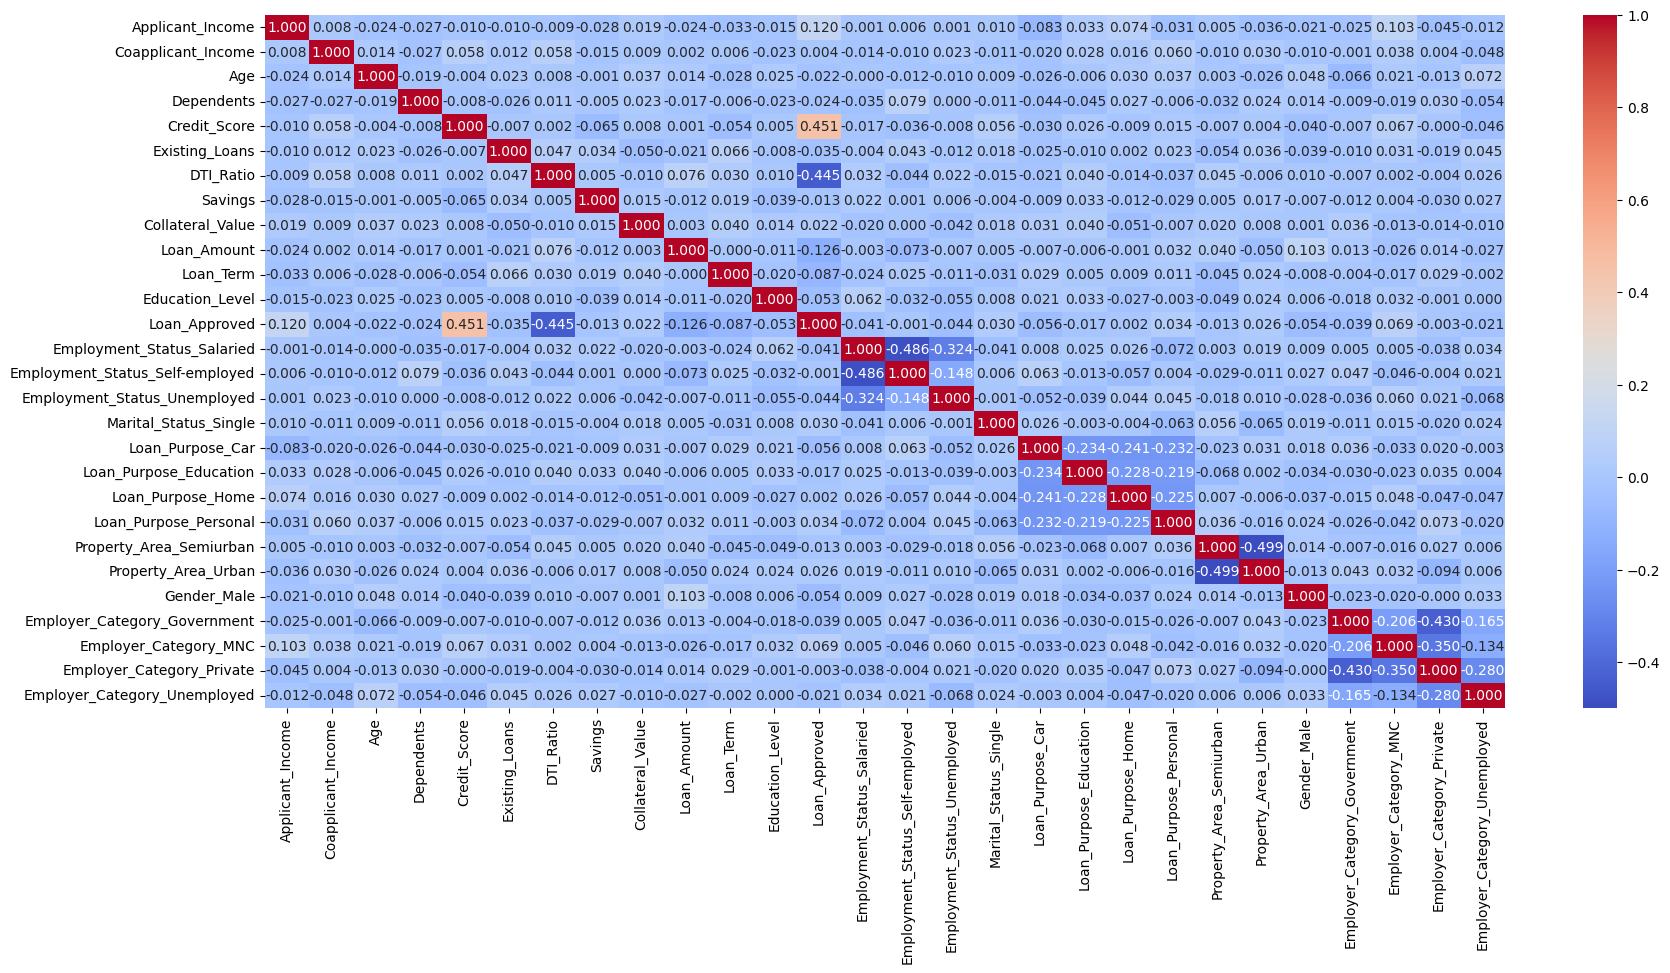

In [18]:
plt.figure(figsize=(20,9))
sns.heatmap(corr_matrix,annot=True,fmt='.3f',cmap='coolwarm')

In [19]:
num_cols.corr()['Loan_Approved'].sort_values(ascending=False)

Loan_Approved                      1.000000
Credit_Score                       0.451175
Applicant_Income                   0.119796
Employer_Category_MNC              0.069049
Loan_Purpose_Personal              0.034043
Marital_Status_Single              0.030182
Property_Area_Urban                0.025963
Collateral_Value                   0.021868
Coapplicant_Income                 0.004230
Loan_Purpose_Home                  0.002118
Employment_Status_Self-employed   -0.001337
Employer_Category_Private         -0.003347
Property_Area_Semiurban           -0.012967
Savings                           -0.013437
Loan_Purpose_Education            -0.016684
Employer_Category_Unemployed      -0.021468
Age                               -0.022343
Dependents                        -0.023811
Existing_Loans                    -0.034794
Employer_Category_Government      -0.039187
Employment_Status_Salaried        -0.041428
Employment_Status_Unemployed      -0.044464
Education_Level                 

In [20]:
X= df.drop("Loan_Approved",axis=1)
y=df["Loan_Approved"]
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.2,random_state=42)

In [21]:
from sklearn.preprocessing import StandardScaler
scal=StandardScaler()
X_train_scaled= scal.fit_transform(X_train)
X_test_scaled= scal.transform(X_test)

In [23]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,precision_score,confusion_matrix,recall_score
lg= LogisticRegression()
lg.fit(X_train_scaled,y_train)
y_pred=lg.predict(X_test_scaled)
print("accuracy_score=", accuracy_score(y_test,y_pred))
print("precision_score=", precision_score(y_test,y_pred))
print("recall_score=", recall_score(y_test,y_pred))
print("confusion_matrix=", confusion_matrix(y_test,y_pred))

accuracy_score= 0.865
precision_score= 0.7833333333333333
recall_score= 0.7704918032786885
confusion_matrix= [[126  13]
 [ 14  47]]


In [25]:
from sklearn.naive_bayes import GaussianNB
nb= GaussianNB()
nb.fit(X_train_scaled,y_train)
y_pred=nb.predict(X_test_scaled)
print("accuracy_score=", accuracy_score(y_test,y_pred))
print("precision_score=", precision_score(y_test,y_pred))
print("recall_score=", recall_score(y_test,y_pred))
print("confusion_matrix=", confusion_matrix(y_test,y_pred))

accuracy_score= 0.865
precision_score= 0.8035714285714286
recall_score= 0.7377049180327869
confusion_matrix= [[128  11]
 [ 16  45]]


In [32]:
from sklearn.neighbors import KNeighborsClassifier
n_neighbors=[3,4,5,6,7,8,9,10,11,12,13,14,15,16]
for neighbor in n_neighbors:
    knn= KNeighborsClassifier(n_neighbors=neighbor)
    knn.fit(X_train_scaled,y_train)
    y_pred=knn.predict(X_test_scaled)
    best_neighbor=float("-inf")
    if precision_score(y_test,y_pred)>best_neighbor:
        best_pecision = precision_score(y_test, y_pred)
        best_k= neighbor
knn= KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train_scaled,y_train)
print("accuracy_score=", accuracy_score(y_test,y_pred))
print("precision_score=", precision_score(y_test,y_pred))
print("recall_score=", recall_score(y_test,y_pred))
print("confusion_matrix=", confusion_matrix(y_test,y_pred))

accuracy_score= 0.77
precision_score= 0.7777777777777778
recall_score= 0.3442622950819672
confusion_matrix= [[133   6]
 [ 40  21]]
